<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_23_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import keras
from keras import layers

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [9]:
#Veriyi Çağırma ve Tanıma

digits = load_digits()

X = digits.images
y = digits.target

In [13]:
print("X Şekli:", X.shape)
print("y Şekli:", y.shape)
#

X Şekli: (1797, 8, 8)
y Şekli: (1797,)


In [15]:
print("Sınıflar:",np.unique(y))

Sınıflar: [0 1 2 3 4 5 6 7 8 9]


In [17]:
#bir resim aslında ne demek?
print(X[0])

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


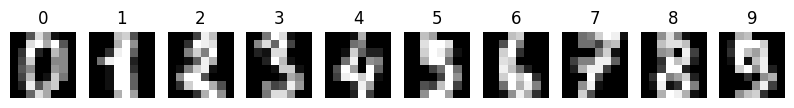

In [19]:
#İLK 10 Resmi Çizdir

plt.figure(figsize=(10,10))
for i in range(10):
    plt.subplot(1,10,i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title(y[i])
    plt.axis("off")

plt.show()
#

In [21]:
#Sınıflar Dengeli mi?

print("Her rakamdan kaç resim var?")
print(np.bincount(y)) #her sayının kaç adet geçtiği

Her rakamdan kaç resim var?
[178 182 177 183 181 182 181 179 174 180]


In [23]:
#VERİYİ HAZIRLAMA - Ölçekleme - train ve test olarak ayırabiliriz.

#ÖLÇEKLEME
print("En küçük değer:", X.min())
print("En büyük değer:", X.max())

X = X / 16.0

En küçük değer: 0.0
En büyük değer: 16.0


In [25]:
print("Yeni en büyük değer ölçekleme sonrası:", X.max()) # Verimiz sıfır ile 1 arasına ölçeklenmiş oldu.

Yeni en büyük değer ölçekleme sonrası: 1.0


In [26]:
# KANAL BOYUTU EKLEME

X = X.reshape(-1, 8, 8, 1) # CNN mimarisinde kanal boyutu eklenmesi gerekiyor. Sayıların anlamı sırası ile -1 noyutu sne hesapla 1797 adet var ona bakacak. 8, 8 boyut, 1 de gri olduğu için tek kanal. renkli olsa 3 kanal olacaktı.
print("Yeni Şekil:", X.shape)

Yeni Şekil: (1797, 8, 8, 1)


In [28]:
# Train ve Test olarak ayırma

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Eğitim:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
#

Eğitim: (1437, 8, 8, 1) (1437,)
Test: (360, 8, 8, 1) (360,)


In [30]:
#MODELİ KURMA (CNN Mimarisi)

model = keras.Sequential([
    keras.Input(shape=(8, 8, 1)), # Modele girecek resmin şekli
    layers.Conv2D(8, (3, 3), activation="relu"), # Evrişim katmanı
    layers.MaxPooling2D((2, 2)), # her 2*2 bölgeden en büyük değeri al. Boyutu yarıya indir.
    layers.Flatten(), # tabloyu tek satıra diz.
    layers.Dense(10, activation="softmax") # 10 rakamın olasılığını üret.

])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 8)        │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 72)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           730 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 810 (3.16 KB)

 Trainable params: 810 (3.16 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
# DERLEME

model.compile(
    optimizer="adam", # ağırlıkları güncelleme yöntemi. öğrenme hızını kendi ayarlıyor. Çoğu problemde iyi bir başlangıçtır.
    loss="sparse_categorical_crossentropy", #çoklu sınıflandırmanın kayıp fonksiyonu
    metrics=["accuracy"]  #eğitim sırasında doğruluğu gösterir
)

In [35]:
# MODELİ EĞİT
gecmiş = model.fit(
    X_train, y_train,
    epochs=40, #eğitim verisinin tamamı modelden 40 kez geçecek.
    batch_size=32, # ağırlıklar her 32 resimde bir güncellenir.
    validation_split=0.2, #eğitim verisinin %20 si doğrulama için ayrılır.
)


Epoch 1/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1836 - loss: 2.2865 - val_accuracy: 0.2361 - val_loss: 2.2168
Epoch 2/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2663 - loss: 2.1870 - val_accuracy: 0.3576 - val_loss: 2.1307
Epoch 3/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3899 - loss: 2.0780 - val_accuracy: 0.5069 - val_loss: 2.0107
Epoch 4/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6153 - loss: 1.9318 - val_accuracy: 0.6806 - val_loss: 1.8451
Epoch 5/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7459 - loss: 1.7433 - val_accuracy: 0.7431 - val_loss: 1.6346
Epoch 6/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7981 - loss: 1.5128 - val_accuracy: 0.7535 - val_loss: 1.4020
Epoch 7/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8590 - loss: 1.2697 - val_accuracy: 0.7882 - val_loss: 1.1761
Epoch 8/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8660 - loss: 1.0510 - val_accuracy: 0.8194 - val_loss

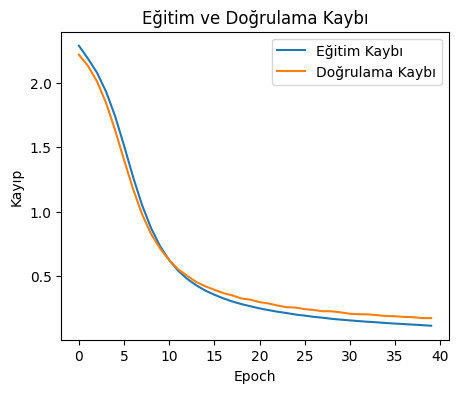

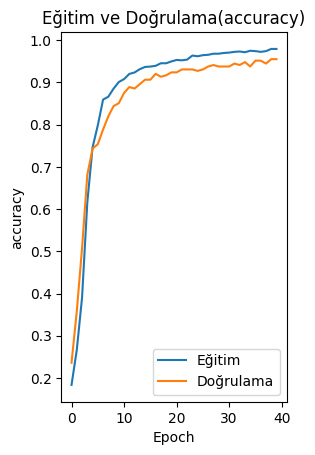

In [40]:
# ÖĞRENME EĞRİLERİNİ ÇİZME

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(gecmiş.history["loss"], label="Eğitim Kaybı")
plt.plot(gecmiş.history["val_loss"], label="Doğrulama Kaybı")
plt.title("Eğitim ve Doğrulama Kaybı")
plt.xlabel("Epoch")
plt.ylabel("Kayıp")
plt.legend()
plt.show()

plt.subplot(1, 2, 2)
plt.plot(gecmiş.history["accuracy"], label="Eğitim")
plt.plot(gecmiş.history["val_accuracy"], label="Doğrulama")
plt.title("Eğitim ve Doğrulama(accuracy)")
plt.xlabel("Epoch")
plt.ylabel("accuracy")
plt.legend()

plt.show()

In [42]:
#DEĞERLENDİRME

test_kayip, test_doğruluk = model.evaluate(X_test, y_test)
print("Test Kaybı:", test_kayip)
print("Test Doğruluk:", test_doğruluk)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9583 - loss: 0.1481 
Test Kaybı: 0.14813730120658875
Test Doğruluk: 0.9583333134651184


In [46]:
#Tek bir resim için tahmin

olasiliklar = model.predict(X_test[:1])

print(olasiliklar.round(2))
print("Tahmin:", np.argmax(olasiliklar))
print("Gerçek:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
[[0.   0.   0.   0.   0.   0.96 0.   0.   0.   0.04]]
Tahmin: 5
Gerçek: 5


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


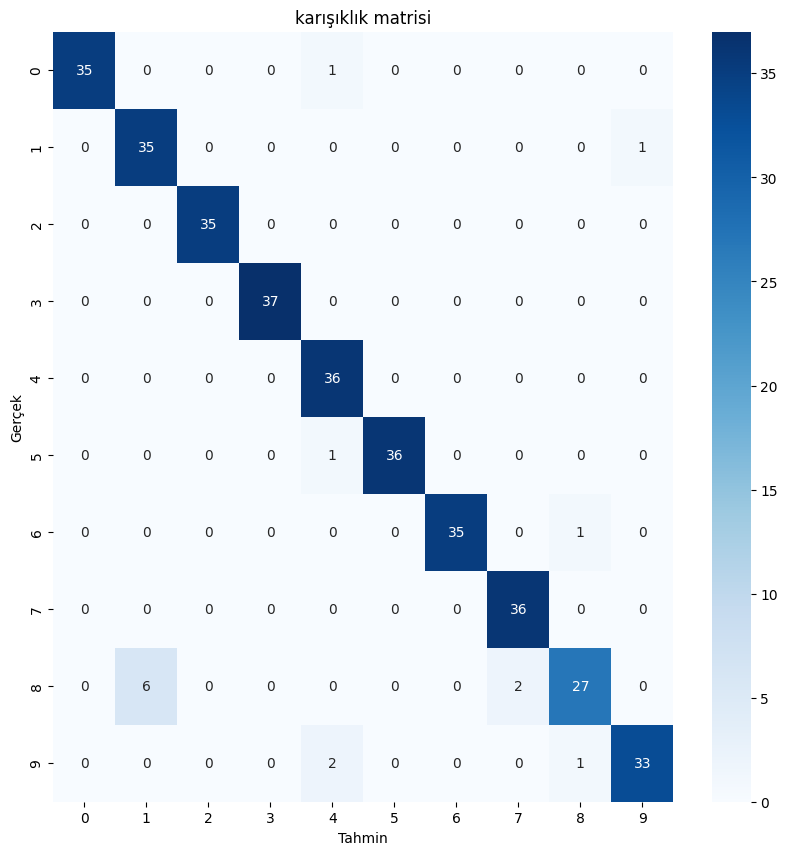

In [48]:
#Karışıklık matrisi

tum_olasiliklar = model.predict(X_test)
y_tahmin = np.argmax(tum_olasiliklar, axis=1)

cm = confusion_matrix(y_test, y_tahmin)

plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("karışıklık matrisi")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.show()

In [50]:
#Sınıf bazlı rapor

print(classification_report(y_test, y_tahmin))
#precision - 1 dediğimiz resimlerin ne kadarı gerçekten 1
#recall - Gerçek 8 lerin ne kadarını bulduk?
# test verisinde o rakamdan kaç resim olduğu.

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.85      0.97      0.91        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.90      1.00      0.95        36
           5       1.00      0.97      0.99        37
           6       1.00      0.97      0.99        36
           7       0.95      1.00      0.97        36
           8       0.93      0.77      0.84        35
           9       0.97      0.92      0.94        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360

